In [3]:
import math

def summation_unit(inputs, weights):
    total = 0
    for x, w in zip(inputs, weights):
        total += x * w
    return total

def step_activation(y):
    if y >= 0:
        return 1
    else:
        return 0

def bipolar_step_activation(y):
    if y >= 0:
        return 1
    else:
        return -1

def sigmoid_activation(y):
    return 1 / (1 + math.exp(-y))

def tanh_activation(y):
    return math.tanh(y)

def relu_activation(y):
    return max(0, y)

def leaky_relu_activation(y):
    if y > 0:
        return y
    else:
        return 0.01 * y

def comparator_unit(target, output):
    return target - output

inputs = [1, 2]
weights = [0.5, 0.25]

print("Summation:", summation_unit(inputs, weights))
print("Step:", step_activation(-2))
print("Bipolar Step:", bipolar_step_activation(-2))
print("Sigmoid:", sigmoid_activation(0))
print("Tanh:", tanh_activation(0))
print("ReLU:", relu_activation(-2))
print("Leaky ReLU:", leaky_relu_activation(-2))
print("Comparator Error:", comparator_unit(1, 0))

Summation: 1.0
Step: 0
Bipolar Step: -1
Sigmoid: 0.5
Tanh: 0.0
ReLU: 0
Leaky ReLU: -0.02
Comparator Error: 1


In [5]:
import numpy as np

def summation_unit(inputs, weights):
    total = 0
    for x, w in zip(inputs, weights):
        total += x * w
    return total

def step_activation(y):
    if y >= 0:
        return 1
    else:
        return 0

def perceptron_and():
    X = np.array([
        [1, 0, 0],
        [1, 0, 1],
        [1, 1, 0],
        [1, 1, 1]
    ])

    T = np.array([0, 0, 0, 1])

    weights = np.array([1.0, -0.2, -0.75])
    learning_rate = 0.05

    epoch_errors = []

    for epoch in range(1, 1001):
        total_error = 0

        for x, target in zip(X, T):
            yin = summation_unit(x, weights)
            output = step_activation(yin)

            error = target - output
            total_error += error ** 2

            weights = weights + learning_rate * error * x

        epoch_errors.append(total_error)

        if total_error <= 0.002:
            break

    print("Converged after", epoch, "epochs")
    print("Final weights:", weights)
    print("Final error:", total_error)

    print("\nEpoch-wise error:")
    for i, error in enumerate(epoch_errors, 1):
        print("Epoch", i, ":", error)

    return weights, epoch_errors

weights, errors = perceptron_and()

Converged after 25 epochs
Final weights: [-0.1   0.1   0.05]
Final error: 0

Epoch-wise error:
Epoch 1 : 4
Epoch 2 : 4
Epoch 3 : 3
Epoch 4 : 3
Epoch 5 : 3
Epoch 6 : 3
Epoch 7 : 3
Epoch 8 : 3
Epoch 9 : 3
Epoch 10 : 3
Epoch 11 : 3
Epoch 12 : 3
Epoch 13 : 3
Epoch 14 : 2
Epoch 15 : 3
Epoch 16 : 3
Epoch 17 : 2
Epoch 18 : 3
Epoch 19 : 3
Epoch 20 : 2
Epoch 21 : 3
Epoch 22 : 3
Epoch 23 : 2
Epoch 24 : 1
Epoch 25 : 0


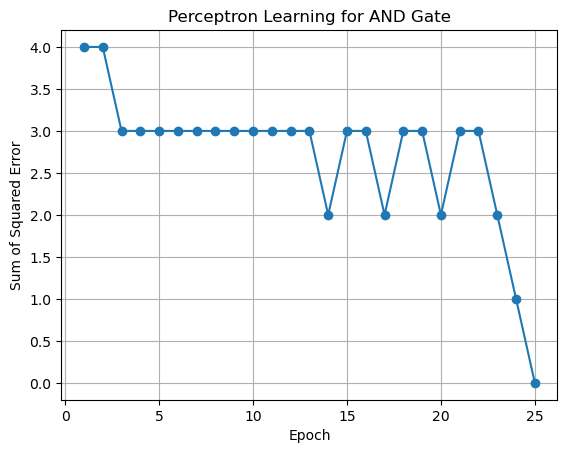

In [7]:
import matplotlib.pyplot as plt

plt.plot(range(1, len(errors) + 1), errors, marker='o')
plt.xlabel("Epoch")
plt.ylabel("Sum of Squared Error")
plt.title("Perceptron Learning for AND Gate")
plt.grid()
plt.show()

In [9]:
import numpy as np
import math
import matplotlib.pyplot as plt

X = np.array([
    [1, 0, 0],
    [1, 0, 1],
    [1, 1, 0],
    [1, 1, 1]
])

T = np.array([0, 0, 0, 1])

learning_rate = 0.05

def bipolar_step(y):
    if y >= 0:
        return 1
    else:
        return -1

def sigmoid(y):
    return 1 / (1 + math.exp(-y))

def relu(y):
    return max(0, y)

def train_perceptron(activation):
    weights = np.array([1.0, -0.2, -0.75])
    errors = []

    for epoch in range(1, 1001):
        total_error = 0

        for x, target in zip(X, T):
            yin = np.dot(x, weights)
            output = activation(yin)

            error = target - output
            total_error += error ** 2

            weights = weights + learning_rate * error * x

        errors.append(total_error)

        if total_error <= 0.002:
            return epoch, weights, errors

    return 1000, weights, errors


bipolar_epochs, bipolar_weights, bipolar_errors = train_perceptron(bipolar_step)
sigmoid_epochs, sigmoid_weights, sigmoid_errors = train_perceptron(sigmoid)
relu_epochs, relu_weights, relu_errors = train_perceptron(relu)

print("Bipolar Step:")
print("Epochs:", bipolar_epochs)
print("Final weights:", bipolar_weights)
print("Final error:", bipolar_errors[-1])

print("\nSigmoid:")
print("Epochs:", sigmoid_epochs)
print("Final weights:", sigmoid_weights)
print("Final error:", sigmoid_errors[-1])

print("\nReLU:")
print("Epochs:", relu_epochs)
print("Final weights:", relu_weights)
print("Final error:", relu_errors[-1])

print("\nComparison:")
print("Bipolar Step:", bipolar_epochs, "epochs")
print("Sigmoid:", sigmoid_epochs, "epochs")
print("ReLU:", relu_epochs, "epochs")

Bipolar Step:
Epochs: 1000
Final weights: [-9.85322934e-16 -1.38777878e-17  5.00000000e-02]
Final error: 3

Sigmoid:
Epochs: 1000
Final weights: [-6.48225051  4.20333459  4.19716405]
Final error: 0.03408181600493644

ReLU:
Epochs: 336
Final weights: [-0.92826333  0.95151056  0.95017108]
Final error: 0.0019665595226949595

Comparison:
Bipolar Step: 1000 epochs
Sigmoid: 1000 epochs
ReLU: 336 epochs


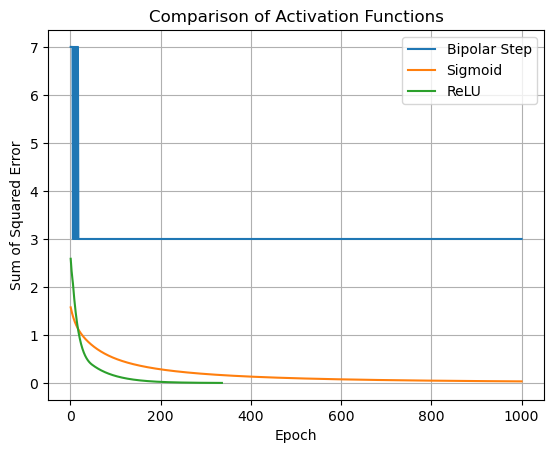

In [11]:
plt.plot(range(1, len(bipolar_errors) + 1), bipolar_errors, label="Bipolar Step")
plt.plot(range(1, len(sigmoid_errors) + 1), sigmoid_errors, label="Sigmoid")
plt.plot(range(1, len(relu_errors) + 1), relu_errors, label="ReLU")

plt.xlabel("Epoch")
plt.ylabel("Sum of Squared Error")
plt.title("Comparison of Activation Functions")
plt.legend()
plt.grid()
plt.show()

In [13]:
import numpy as np
import matplotlib.pyplot as plt

X = np.array([
    [1, 0, 0],
    [1, 0, 1],
    [1, 1, 0],
    [1, 1, 1]
])

T = np.array([0, 0, 0, 1])

initial_weights = np.array([1.0, -0.2, -0.75])

def step_activation(y):
    if y >= 0:
        return 1
    else:
        return 0

def train_perceptron(learning_rate):
    weights = initial_weights.copy()

    for epoch in range(1, 1001):
        total_error = 0

        for x, target in zip(X, T):
            yin = np.dot(x, weights)
            output = step_activation(yin)

            error = target - output
            total_error += error ** 2

            weights = weights + learning_rate * error * x

        if total_error <= 0.002:
            return epoch

    return 1000

learning_rates = np.arange(0.1, 1.0, 0.1)
epochs = []

for lr in learning_rates:
    epoch = train_perceptron(lr)
    epochs.append(epoch)

print("Learning Rate vs Epochs")
print("----------------------")

for lr, epoch in zip(learning_rates, epochs):
    print("Learning Rate:", round(lr, 1), " Epochs:", epoch)

Learning Rate vs Epochs
----------------------
Learning Rate: 0.1  Epochs: 16
Learning Rate: 0.2  Epochs: 11
Learning Rate: 0.3  Epochs: 7
Learning Rate: 0.4  Epochs: 6
Learning Rate: 0.5  Epochs: 6
Learning Rate: 0.6  Epochs: 7
Learning Rate: 0.7  Epochs: 7
Learning Rate: 0.8  Epochs: 8
Learning Rate: 0.9  Epochs: 5


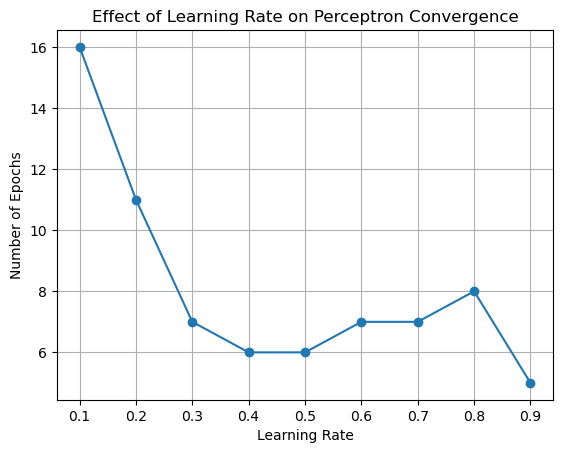

In [15]:
plt.plot(learning_rates, epochs, marker='o')
plt.xlabel("Learning Rate")
plt.ylabel("Number of Epochs")
plt.title("Effect of Learning Rate on Perceptron Convergence")
plt.grid()
plt.show()

Learning Rate	Iterations
0.1 		 16
0.2 		 11
0.3 		 7
0.4 		 6
0.5 		 6
0.6 		 7
0.7 		 7
0.8 		 8
0.9 		 5


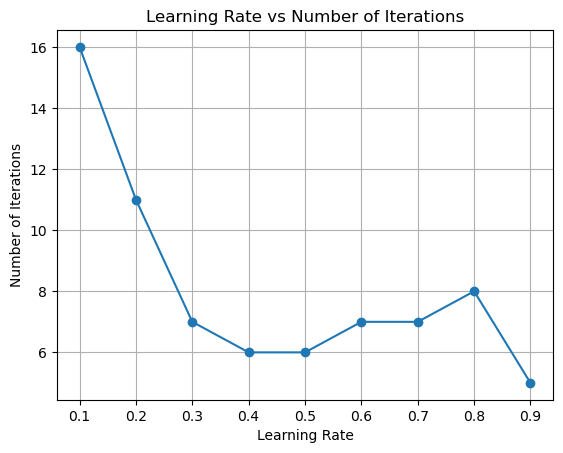

In [17]:
import numpy as np
import matplotlib.pyplot as plt

X = np.array([
    [1, 0, 0],
    [1, 0, 1],
    [1, 1, 0],
    [1, 1, 1]
])

T = np.array([0, 0, 0, 1])

initial_weights = np.array([1.0, -0.2, -0.75])

def step_activation(y):
    if y >= 0:
        return 1
    else:
        return 0

def train_perceptron(learning_rate):
    weights = initial_weights.copy()

    for epoch in range(1, 1001):
        total_error = 0

        for x, target in zip(X, T):
            yin = np.dot(x, weights)
            output = step_activation(yin)

            error = target - output
            total_error += error ** 2

            weights = weights + learning_rate * error * x

        if total_error <= 0.002:
            return epoch

    return 1000

learning_rates = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

iterations = []

for lr in learning_rates:
    epochs = train_perceptron(lr)
    iterations.append(epochs)

print("Learning Rate\tIterations")

for lr, iteration in zip(learning_rates, iterations):
    print(lr, "\t\t", iteration)

plt.plot(learning_rates, iterations, marker='o')
plt.xlabel("Learning Rate")
plt.ylabel("Number of Iterations")
plt.title("Learning Rate vs Number of Iterations")
plt.grid()
plt.show()

In [19]:
import numpy as np
import math
import matplotlib.pyplot as plt

X = np.array([
    [1, 0, 0],
    [1, 0, 1],
    [1, 1, 0],
    [1, 1, 1]
])

T = np.array([0, 1, 1, 0])

initial_weights = np.array([1.0, -0.2, -0.75])
learning_rate = 0.05


def step_activation(y):
    if y >= 0:
        return 1
    else:
        return 0


def bipolar_step_activation(y):
    if y >= 0:
        return 1
    else:
        return -1


def sigmoid_activation(y):
    return 1 / (1 + math.exp(-y))


def relu_activation(y):
    return max(0, y)


def train_perceptron(activation):
    weights = initial_weights.copy()
    errors = []

    for epoch in range(1, 1001):
        total_error = 0

        for x, target in zip(X, T):
            yin = np.dot(x, weights)
            output = activation(yin)

            error = target - output
            total_error += error ** 2

            weights = weights + learning_rate * error * x

        errors.append(total_error)

        if total_error <= 0.002:
            return epoch, weights, errors

    return 1000, weights, errors


step_epochs, step_weights, step_errors = train_perceptron(step_activation)
bipolar_epochs, bipolar_weights, bipolar_errors = train_perceptron(bipolar_step_activation)
sigmoid_epochs, sigmoid_weights, sigmoid_errors = train_perceptron(sigmoid_activation)
relu_epochs, relu_weights, relu_errors = train_perceptron(relu_activation)


print("STEP ACTIVATION")
print("Epochs:", step_epochs)
print("Final weights:", step_weights)
print("Final error:", step_errors[-1])

print("\nBIPOLAR STEP")
print("Epochs:", bipolar_epochs)
print("Final weights:", bipolar_weights)
print("Final error:", bipolar_errors[-1])

print("\nSIGMOID")
print("Epochs:", sigmoid_epochs)
print("Final weights:", sigmoid_weights)
print("Final error:", sigmoid_errors[-1])

print("\nRELU")
print("Epochs:", relu_epochs)
print("Final weights:", relu_weights)
print("Final error:", relu_errors[-1])

STEP ACTIVATION
Epochs: 1000
Final weights: [ 0.1 -0.1 -0.1]
Final error: 4

BIPOLAR STEP
Epochs: 1000
Final weights: [ 0.2  -0.1  -0.15]
Final error: 6

SIGMOID
Epochs: 1000
Final weights: [ 0.02557895 -0.05084922 -0.025536  ]
Final error: 1.0254757465770352

RELU
Epochs: 1000
Final weights: [ 0.52631579 -0.05263158 -0.02631579]
Final error: 1.1080332409972302


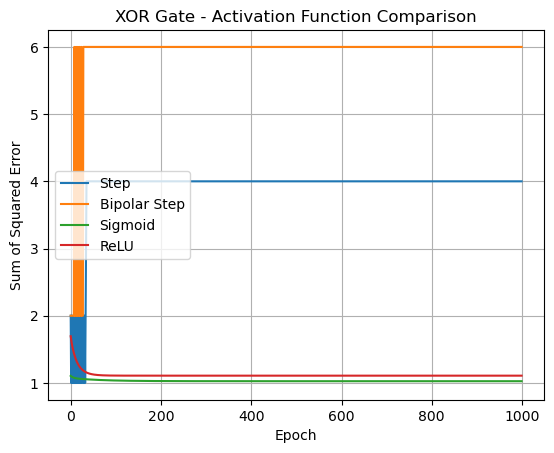

In [21]:
plt.plot(step_errors, label="Step")
plt.plot(bipolar_errors, label="Bipolar Step")
plt.plot(sigmoid_errors, label="Sigmoid")
plt.plot(relu_errors, label="ReLU")

plt.xlabel("Epoch")
plt.ylabel("Sum of Squared Error")
plt.title("XOR Gate - Activation Function Comparison")
plt.legend()
plt.grid()
plt.show()

In [23]:
import numpy as np

X = np.array([
    [12, 20, 3, 386],
    [16, 3, 6, 289],
    [27, 6, 2, 393],
    [19, 1, 2, 110],
    [24, 4, 2, 280],
    [22, 4, 5, 167],
    [15, 4, 2, 271],
    [18, 4, 2, 274],
    [21, 1, 4, 148],
    [16, 2, 4, 198]
], dtype=float)

Y = np.array([1, 1, 1, 0, 1, 0, 1, 1, 0, 0])


def sigmoid(x):
    return 1 / (1 + np.exp(-x))


def train_perceptron(X, Y, learning_rate=0.05, epochs=10000):
    weights = np.zeros(X.shape[1])
    bias = 0.0

    for epoch in range(epochs):

        total_error = 0

        for x, target in zip(X, Y):

            z = np.dot(x, weights) + bias
            output = sigmoid(z)

            error = target - output
            total_error += error ** 2

            weights = weights + learning_rate * error * output * (1 - output) * x
            bias = bias + learning_rate * error * output * (1 - output)

        if total_error <= 0.002:
            break

    return weights, bias, epoch + 1


# Normalize the features
X_min = X.min(axis=0)
X_max = X.max(axis=0)

X_normalized = (X - X_min) / (X_max - X_min)


weights, bias, epochs = train_perceptron(
    X_normalized,
    Y,
    learning_rate=0.05,
    epochs=10000
)


print("Final weights:", weights)
print("Final bias:", bias)
print("Number of epochs:", epochs)


print("\nPredictions:")

for i, x in enumerate(X_normalized):

    z = np.dot(x, weights) + bias
    probability = sigmoid(z)

    if probability >= 0.5:
        prediction = "Yes"
    else:
        prediction = "No"

    print(
        "Customer:", i + 1,
        "Probability:", round(probability, 4),
        "Prediction:", prediction,
        "Actual:", "Yes" if Y[i] == 1 else "No"
    )

Final weights: [-0.76765651  2.86515701 -1.44722735 12.24703452]
Final bias: -4.517191570565058
Number of epochs: 10000

Predictions:
Customer: 1 Probability: 1.0 Prediction: Yes Actual: Yes
Customer: 2 Probability: 0.8675 Prediction: Yes Actual: Yes
Customer: 3 Probability: 0.9996 Prediction: Yes Actual: Yes
Customer: 4 Probability: 0.0076 Prediction: No Actual: No
Customer: 5 Probability: 0.9357 Prediction: Yes Actual: Yes
Customer: 6 Probability: 0.0393 Prediction: No Actual: No
Customer: 7 Probability: 0.9399 Prediction: Yes Actual: Yes
Customer: 8 Probability: 0.9385 Prediction: Yes Actual: Yes
Customer: 9 Probability: 0.017 Prediction: No Actual: No
Customer: 10 Probability: 0.1845 Prediction: No Actual: No


In [25]:
import numpy as np

X = np.array([
    [12, 20, 3, 386],
    [16, 3, 6, 289],
    [27, 6, 2, 393],
    [19, 1, 2, 110],
    [24, 4, 2, 280],
    [22, 4, 5, 167],
    [15, 4, 2, 271],
    [18, 4, 2, 274],
    [21, 1, 4, 148],
    [16, 2, 4, 198]
], dtype=float)

Y = np.array([1, 1, 1, 0, 1, 0, 1, 1, 0, 0])


# Normalize the features
X_min = X.min(axis=0)
X_max = X.max(axis=0)

X_normalized = (X - X_min) / (X_max - X_min)


# Add bias column
X_bias = np.column_stack((np.ones(X_normalized.shape[0]), X_normalized))


# Calculate pseudo-inverse
X_pseudo = np.linalg.pinv(X_bias)


# Calculate weights
weights = np.dot(X_pseudo, Y)


# Calculate predictions
predictions = np.dot(X_bias, weights)


print("Pseudo-Inverse Weights:")
print(weights)

print("\nPredictions:")

for i, prediction in enumerate(predictions):
    if prediction >= 0.5:
        result = "Yes"
    else:
        result = "No"

    actual = "Yes" if Y[i] == 1 else "No"

    print(
        "Customer:", i + 1,
        "Predicted:", round(prediction, 4),
        "Class:", result,
        "Actual:", actual
    )


# Calculate accuracy
binary_predictions = (predictions >= 0.5).astype(int)

accuracy = np.mean(binary_predictions == Y) * 100

print("\nAccuracy:", accuracy, "%")

Pseudo-Inverse Weights:
[ 0.18463747 -0.43415341 -0.76145755 -0.24463241  1.69411546]

Predictions:
Customer: 1 Predicted: 1.0142 Class: Yes Actual: Yes
Customer: 2 Predicted: 0.8156 Class: Yes Actual: Yes
Customer: 3 Predicted: 1.2442 Class: Yes Actual: Yes
Customer: 4 Predicted: -0.018 Class: No Actual: No
Customer: 5 Predicted: 0.7348 Class: Yes Actual: Yes
Customer: 6 Predicted: -0.0673 Class: No Actual: No
Customer: 7 Predicted: 0.9414 Class: Yes Actual: Yes
Customer: 8 Predicted: 0.8725 Class: Yes Actual: Yes
Customer: 9 Predicted: 0.0293 Class: No Actual: No
Customer: 10 Predicted: 0.4333 Class: No Actual: No

Accuracy: 100.0 %


In [27]:
import numpy as np

X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
], dtype=float)

T = np.array([0, 0, 0, 1], dtype=float)

learning_rate = 0.05
max_epochs = 1000

np.random.seed(42)

V = np.random.uniform(-0.05, 0.05, (2, 2))
W = np.random.uniform(-0.05, 0.05, 2)


def sigmoid(x):
    return 1 / (1 + np.exp(-x))


error_history = []

for epoch in range(1, max_epochs + 1):

    total_error = 0

    for x, target in zip(X, T):

        # Forward propagation

        hidden_input = np.dot(x, V)
        hidden_output = sigmoid(hidden_input)

        output_input = np.dot(hidden_output, W)
        output = sigmoid(output_input)

        # Calculate error

        error = target - output
        total_error += error ** 2

        # Backpropagation

        delta_output = output * (1 - output) * error

        delta_hidden = hidden_output * (1 - hidden_output) * (
            W * delta_output
        )

        # Update hidden-to-output weights

        W = W + learning_rate * delta_output * hidden_output

        # Update input-to-hidden weights

        V = V + learning_rate * np.outer(x, delta_hidden)

    error_history.append(total_error)

    if total_error <= 0.002:
        break


print("Number of epochs:", epoch)
print("Final error:", total_error)

print("\nInput-to-hidden weights:")
print(V)

print("\nHidden-to-output weights:")
print(W)

print("\nPredictions:")

for x, target in zip(X, T):

    hidden_output = sigmoid(np.dot(x, V))
    output = sigmoid(np.dot(hidden_output, W))

    print(
        "Input:", x,
        "Target:", target,
        "Output:", round(output, 4)
    )

Number of epochs: 1000
Final error: 0.5719667512140196

Input-to-hidden weights:
[[-0.83154222 -0.77443232]
 [-0.79070661 -0.81529622]]

Hidden-to-output weights:
[-1.63163241 -1.5982388 ]

Predictions:
Input: [0. 0.] Target: 0.0 Output: 0.1659
Input: [0. 1.] Target: 0.0 Output: 0.2691
Input: [1. 0.] Target: 0.0 Output: 0.2691
Input: [1. 1.] Target: 1.0 Output: 0.3682


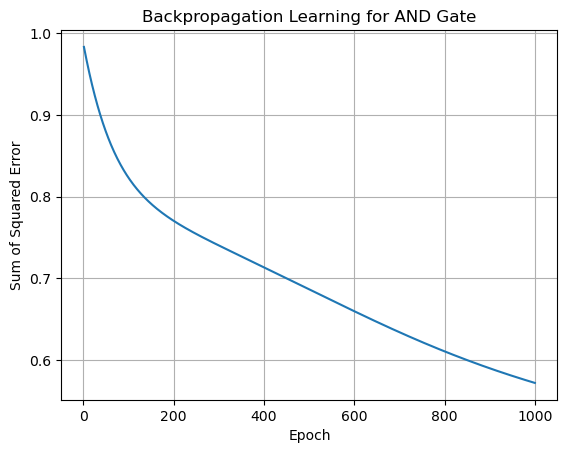

In [29]:
import matplotlib.pyplot as plt

plt.plot(range(1, len(error_history) + 1), error_history)

plt.xlabel("Epoch")
plt.ylabel("Sum of Squared Error")
plt.title("Backpropagation Learning for AND Gate")
plt.grid()
plt.show()

In [31]:
import numpy as np

X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
], dtype=float)

T = np.array([0, 1, 1, 0], dtype=float)

learning_rate = 0.05
max_epochs = 1000

np.random.seed(42)

V = np.random.uniform(-0.05, 0.05, (2, 2))
W = np.random.uniform(-0.05, 0.05, 2)


def sigmoid(x):
    return 1 / (1 + np.exp(-x))


error_history = []

for epoch in range(1, max_epochs + 1):

    total_error = 0

    for x, target in zip(X, T):

        # Forward propagation

        hidden_input = np.dot(x, V)
        hidden_output = sigmoid(hidden_input)

        output_input = np.dot(hidden_output, W)
        output = sigmoid(output_input)

        # Error

        error = target - output
        total_error += error ** 2

        # Backpropagation

        delta_output = output * (1 - output) * error

        delta_hidden = hidden_output * (1 - hidden_output) * (
            W * delta_output
        )

        # Weight updates

        W = W + learning_rate * delta_output * hidden_output

        V = V + learning_rate * np.outer(x, delta_hidden)

    error_history.append(total_error)

    if total_error <= 0.002:
        break


print("Number of epochs:", epoch)
print("Final error:", total_error)

print("\nInput-to-hidden weights:")
print(V)

print("\nHidden-to-output weights:")
print(W)

print("\nPredictions:")

for x, target in zip(X, T):

    hidden_output = sigmoid(np.dot(x, V))
    output = sigmoid(np.dot(hidden_output, W))

    print(
        "Input:", x,
        "Target:", target,
        "Output:", round(output, 4)
    )

Number of epochs: 1000
Final error: 1.0015777742108816

Input-to-hidden weights:
[[-0.01753263  0.03994571]
 [ 0.01323074 -0.0002133 ]]

Hidden-to-output weights:
[-2.01398587e-04  3.40419258e-05]

Predictions:
Input: [0. 0.] Target: 0.0 Output: 0.5
Input: [0. 1.] Target: 1.0 Output: 0.5
Input: [1. 0.] Target: 1.0 Output: 0.5
Input: [1. 1.] Target: 0.0 Output: 0.5


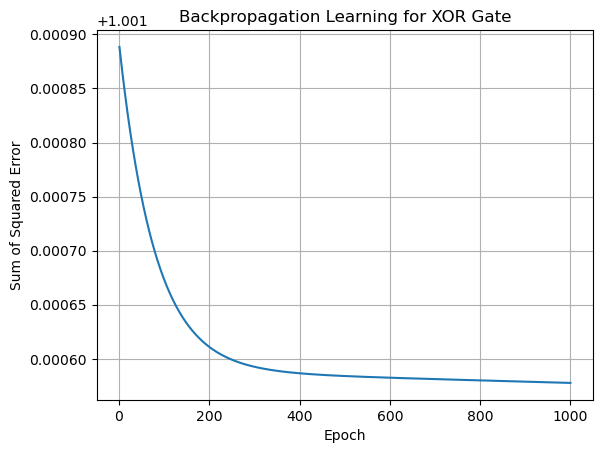

In [33]:
import matplotlib.pyplot as plt

plt.plot(range(1, len(error_history) + 1), error_history)

plt.xlabel("Epoch")
plt.ylabel("Sum of Squared Error")
plt.title("Backpropagation Learning for XOR Gate")
plt.grid()
plt.show()

In [35]:
import numpy as np

X = np.array([
    [1, 0, 0],
    [1, 0, 1],
    [1, 1, 0],
    [1, 1, 1]
], dtype=float)

T = np.array([
    [1, 0],
    [1, 0],
    [1, 0],
    [0, 1]
], dtype=float)

learning_rate = 0.05

weights = np.array([
    [1.0, -0.2, -0.75],
    [1.0, -0.2, -0.75]
])

def step_activation(y):
    if y >= 0:
        return 1
    else:
        return 0

error_history = []

for epoch in range(1, 1001):

    total_error = 0

    for x, target in zip(X, T):

        y_in = np.dot(weights, x)

        output = np.array([
            step_activation(y_in[0]),
            step_activation(y_in[1])
        ])

        error = target - output

        total_error += np.sum(error ** 2)

        weights = weights + learning_rate * np.outer(error, x)

    error_history.append(total_error)

    if total_error <= 0.002:
        break

print("Number of epochs:", epoch)
print("Final error:", total_error)

print("\nFinal weights:")
print(weights)

print("\nPredictions:")

for x, target in zip(X, T):

    y_in = np.dot(weights, x)

    output = np.array([
        step_activation(y_in[0]),
        step_activation(y_in[1])
    ])

    print(
        "Input:", x[1:],
        "Target:", target.astype(int),
        "Output:", output
    )

Number of epochs: 25
Final error: 0.0

Final weights:
[[ 0.95 -0.25 -0.8 ]
 [-0.1   0.1   0.05]]

Predictions:
Input: [0. 0.] Target: [1 0] Output: [1 0]
Input: [0. 1.] Target: [1 0] Output: [1 0]
Input: [1. 0.] Target: [1 0] Output: [1 0]
Input: [1. 1.] Target: [0 1] Output: [0 1]


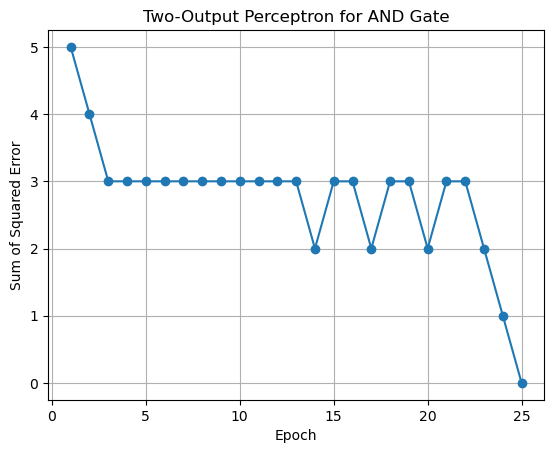

In [37]:
import matplotlib.pyplot as plt

plt.plot(range(1, len(error_history) + 1), error_history, marker='o')

plt.xlabel("Epoch")
plt.ylabel("Sum of Squared Error")
plt.title("Two-Output Perceptron for AND Gate")
plt.grid()
plt.show()

In [39]:
import numpy as np
from sklearn.neural_network import MLPClassifier

X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

and_y = np.array([0, 0, 0, 1])
xor_y = np.array([0, 1, 1, 0])


def train_and_test(X, y, name):
    model = MLPClassifier(
        hidden_layer_sizes=(2,),
        activation='logistic',
        learning_rate_init=0.05,
        max_iter=10000,
        random_state=42
    )

    model.fit(X, y)

    predictions = model.predict(X)

    print(name)
    print("Predictions:", predictions)
    print("Actual:", y)
    print("Iterations:", model.n_iter_)
    print("Accuracy:", model.score(X, y))
    print()


train_and_test(X, and_y, "AND Gate")
train_and_test(X, xor_y, "XOR Gate")

AND Gate
Predictions: [0 0 0 1]
Actual: [0 0 0 1]
Iterations: 223
Accuracy: 1.0

XOR Gate
Predictions: [0 1 1 0]
Actual: [0 1 1 0]
Iterations: 272
Accuracy: 1.0

